## Описание

Ноутбук выбирает пул анкет Mini C-BARQ, которые сильнее всего отличаются друг от друга, и присваивает каждой анкете номер класса.

Вход — очищенная таблица [`../datasets/unified/domain_dedup.csv`](../datasets/unified/domain_dedup.csv) из [`01_eda.ipynb`](01_eda.ipynb). Сырые CSV здесь не читаются. Признаки — субшкалы 0–4. KMeans считает расстояние после заполнения пустых шкал медианой среза; в таблицах и на heatmap остаются исходные значения. Из каждого кластера берётся медоид: анкета с минимальной суммой расстояний до остальных членов группы.

Два среза проходят один и тот же путь. **Весь объём** — все строки `domain_dedup`. **Bohland, 10-й день** — `source == bohland_2023` и `wave == d7` (событие REDCap «10 days after adoption»); идентификатор собаки — `raw_dog_id` (Animal ID).

Сначала кластеры строятся по 14 шкалам, `k` от 3 до 8 по максимуму силуэта. Затем шкала `stranger_directed_aggression` убирается, строки с более чем двумя пустыми шкалами отбрасываются, и расчёт повторяется. Устойчивость при фиксированном `k = 3` проверяется попарным adjusted Rand по списку `SEEDS`. Итоговые файлы классов содержат идентификатор собаки и номер кластера, без контактов владельцев.

## Содержание

- **Задача** — вход, два среза, правило для пустых шкал.
- **1. Кластеры и медоиды** — выбор `k` по силуэту и поиск медоида.
- **2. Весь объём** — пул и heatmap по 14 шкалам, `diverse_pool.csv`.
- **3. Bohland, 10-й день** — тот же расчёт на первой анкете, `diverse_pool_bohland_d10.csv`.
- **4. Без `stranger_directed_aggression`, не больше 2 пустых шкал** — фильтр и повтор на всём объёме, проверка силуэта по `SEEDS`.
- **5. Bohland, 10-й день, те же преобразования** — тот же фильтр на волне `d7`.
- **6. Устойчивость при фиксированном `k = 3`** — попарный adjusted Rand по `SEEDS`.
- **7. Выгрузка классов** — `clusters_all.csv` и `clusters_bohland_d10.csv`.

## Задача

Выбрать пул анкет, которые сильнее всего отличаются друг от друга. Кластеры KMeans по 14 субшкалам Mini C-BARQ; из каждого кластера берётся медоид — анкета, ближайшая к остальным членам своей группы.

Вход: [`../datasets/unified/domain_dedup.csv`](../datasets/unified/domain_dedup.csv) — очищенная таблица из [`01_eda.ipynb`](01_eda.ipynb). Сырые CSV здесь не собираются.

Два среза:

1. **Весь объём** — все строки `domain_dedup`.
2. **Bohland, 10-й день** — `source == bohland_2023` и `wave == d7` (событие REDCap «10 days after adoption»). В пуле идентификатор собаки — `raw_dog_id` (Animal ID).

Признаки — только 14 шкал. Пустые шкалы для KMeans заполняются медианой внутри среза. В таблицах пула и на heatmap средних остаются исходные значения.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

sns.set_theme(style="whitegrid")

DATA_PATH = Path("../datasets/unified/domain_dedup.csv")
OUT_DIR = DATA_PATH.parent

SEED = 42
SEEDS = [SEED, 13, 21, 42, 666, 999]

SCALE_COLS = [
    "excitability",
    "stranger_directed_aggression",
    "owner_directed_aggression",
    "dog_directed_aggression",
    "familiar_dog_aggression",
    "stranger_directed_fear",
    "nonsocial_fear",
    "dog_directed_fear",
    "touch_sensitivity",
    "separation_related_problems",
    "attachment_attention_seeking",
    "training_difficulty",
    "chasing",
    "energy",
]
ID_COLS = ["session_id", "dog_id", "source", "wave"]

domain_dedup = pd.read_csv(DATA_PATH)
print(DATA_PATH.resolve())
print("rows", len(domain_dedup), "cols", domain_dedup.shape[1])

/Users/l.tereshchenkova/MIPT/startup/barko-docs/analytics/research_bohland_powell/datasets/unified/domain_dedup.csv
rows 953 cols 39


## 1. Кластеры и медоиды

`k` от 4 до 8, берётся максимум silhouette. Медоид — строка с минимальной суммой евклидовых расстояний до остальных членов кластера. Расстояния считаются по матрице с медианами; в пуле пропуски не подставляются.

In [2]:
def fit_slice(
    frame: pd.DataFrame,
    label: str,
    cols: list[str] | None = None,
    random_state: int = 0,
) -> tuple[pd.DataFrame, pd.DataFrame, dict[int, float]]:
    """KMeans on median-filled scales. Pool and cluster means keep original NaNs."""
    cols = list(SCALE_COLS if cols is None else cols)
    work = frame.reset_index(drop=True).copy()
    filled = work[cols].fillna(work[cols].median())
    if filled.isna().any().any():
        missing = filled.columns[filled.isna().any()].tolist()
        raise ValueError(f"{label}: subscale is empty in the whole slice: {missing}")
    X = filled.to_numpy(dtype=float)

    scores: dict[int, float] = {}
    best_k, best_score, best_labels = None, -1.0, None
    for k in range(3, 9):
        labels = KMeans(n_clusters=k, n_init=10, random_state=random_state).fit_predict(X)
        score = float(silhouette_score(X, labels))
        scores[k] = score
        if score > best_score:
            best_k, best_score, best_labels = k, score, labels

    work["cluster"] = best_labels
    sizes = work.groupby("cluster")["session_id"].transform("size")
    work["cluster_size"] = sizes
    work["n_scales_missing"] = work[cols].isna().sum(axis=1).astype(int)

    medoid_pos = []
    for cluster_id, idx in work.groupby("cluster").groups.items():
        pos = np.array(list(idx))
        block = X[pos]
        dist = np.sqrt(((block[:, None, :] - block[None, :, :]) ** 2).sum(axis=2))
        medoid_pos.append(int(pos[dist.sum(axis=1).argmin()]))
    pool = work.iloc[medoid_pos].sort_values("cluster").copy()

    print(label, "rows", len(work), "chosen k", best_k, "silhouette", round(best_score, 3))
    print(pd.Series(scores, name="silhouette").rename_axis("k").round(3).to_string())
    return work, pool, scores


def pool_table(
    pool: pd.DataFrame,
    extra: list[str] | None = None,
    cols: list[str] | None = None,
) -> pd.DataFrame:
    cols = list(SCALE_COLS if cols is None else cols)
    show = ID_COLS + (extra or []) + ["cluster", "cluster_size", "n_scales_missing"] + cols
    return pool[show].reset_index(drop=True)


def plot_means(labeled: pd.DataFrame, title: str, cols: list[str] | None = None) -> None:
    cols = list(SCALE_COLS if cols is None else cols)
    means = labeled.groupby("cluster")[cols].mean()
    fig, ax = plt.subplots(figsize=(12, 0.55 * len(means) + 2))
    sns.heatmap(means, vmin=0, vmax=4, cmap="YlOrRd", annot=True, fmt=".2f", ax=ax)
    ax.set_title(title)
    fig.tight_layout()
    plt.show()

## 2. Весь объём

Все строки `domain_dedup`, все источники и волны. Анкеты с пустыми субшкалами не отбрасываются.

all rows 953 chosen k 3 silhouette 0.111
k
3    0.111
4    0.085
5    0.083
6    0.085
7    0.079
8    0.080
../datasets/unified/diverse_pool.csv


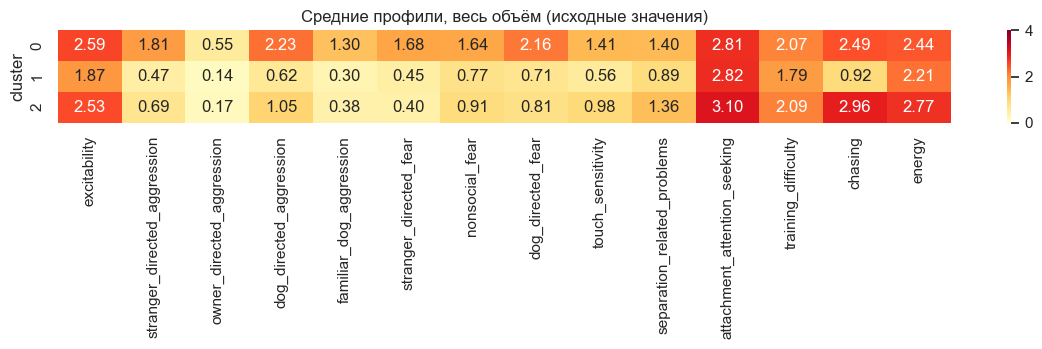

,session_id,dog_id,source,wave,cluster,cluster_size,n_scales_missing,excitability,stranger_directed_aggression,owner_directed_aggression,...,familiar_dog_aggression,stranger_directed_fear,nonsocial_fear,dog_directed_fear,touch_sensitivity,separation_related_problems,attachment_attention_seeking,training_difficulty,chasing,energy
0,serpell_shelter_2009:CO:37248:na,CO:37248,serpell_shelter_2009,NaN,0,226,0,2.5,2.0,0.0,...,1.5,1.0,1.67,2.5,1.5,1.33,3.0,1.33,2.5,2.5
1,serpell_shelter_2009:CA:30344:na,CA:30344,serpell_shelter_2009,NaN,1,380,0,2.0,0.0,0.0,...,0.0,0.5,0.67,1.0,1.0,0.67,2.5,1.67,0.5,2.0
2,serpell_shelter_2009:MO:449574:na,MO:449574,serpell_shelter_2009,NaN,2,347,7,3.0,1.0,0.0,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,3.0,3.0


In [3]:
labeled_all, pool_all, scores_all = fit_slice(domain_dedup, "all")
diverse_pool = pool_table(pool_all)
diverse_pool.to_csv(OUT_DIR / "diverse_pool.csv", index=False)
print(OUT_DIR / "diverse_pool.csv")
plot_means(labeled_all, "Средние профили, весь объём (исходные значения)")
diverse_pool

## 3. Bohland, 10-й день

Только первая анкета: волна `d7`. Одна строка — одна собака. В файле пула есть `raw_dog_id` (Animal ID из consent).

bohland d7 rows 99 unique Animal ID 96
bohland d7 rows 99 chosen k 3 silhouette 0.143
k
3    0.143
4    0.114
5    0.112
6    0.123
7    0.114
8    0.107
../datasets/unified/diverse_pool_bohland_d10.csv


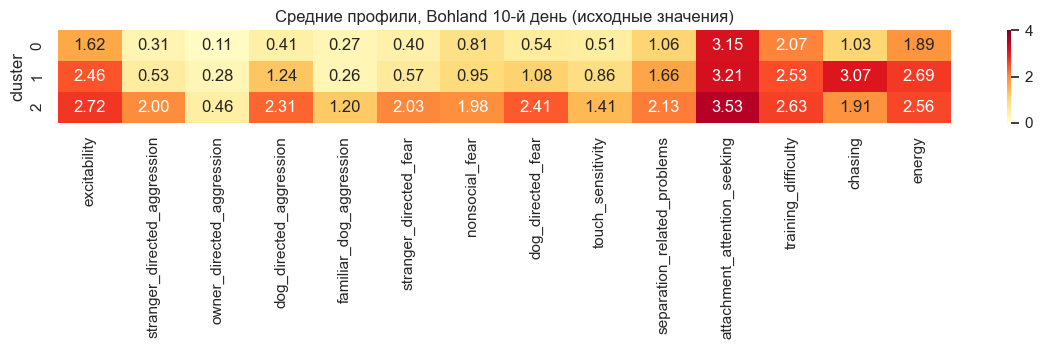

,session_id,dog_id,source,wave,raw_dog_id,cluster,cluster_size,n_scales_missing,excitability,stranger_directed_aggression,...,familiar_dog_aggression,stranger_directed_fear,nonsocial_fear,dog_directed_fear,touch_sensitivity,separation_related_problems,attachment_attention_seeking,training_difficulty,chasing,energy
0,bohland_2023:rec42:d7,rec42,bohland_2023,d7,147023,0,49,13,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,bohland_2023:rec170:d7,rec170,bohland_2023,d7,A47690287,1,34,4,2.5,0.0,...,NaN,0.0,0.33,NaN,NaN,2.00,2.0,2.67,3.0,2.5
2,bohland_2023:rec46:d7,rec46,bohland_2023,d7,147134,2,16,0,3.0,1.0,...,0.5,1.5,2.00,2.0,1.0,1.67,4.0,2.00,1.0,3.0


In [4]:
bohland_d10 = domain_dedup.loc[
    (domain_dedup["source"] == "bohland_2023") & (domain_dedup["wave"] == "d7")
].copy()
print("bohland d7 rows", len(bohland_d10), "unique Animal ID", bohland_d10["raw_dog_id"].nunique())

labeled_d10, pool_d10, scores_d10 = fit_slice(bohland_d10, "bohland d7")
diverse_pool_bohland = pool_table(pool_d10, extra=["raw_dog_id"])
diverse_pool_bohland.to_csv(OUT_DIR / "diverse_pool_bohland_d10.csv", index=False)
print(OUT_DIR / "diverse_pool_bohland_d10.csv")
plot_means(labeled_d10, "Средние профили, Bohland 10-й день (исходные значения)")
diverse_pool_bohland

## 4. Без `stranger_directed_aggression`, не больше 2 пустых шкал

Из признаков убрана `stranger_directed_aggression`. `drop_incomplete(..., max_missing=2)` оставляет строки, где среди оставшихся 13 шкал пустых не больше двух. Для KMeans эти пустые клетки заполняются медианой среза. Оба среза считаются заново: весь объём и Bohland, волна `d7`.

Силуэт для `k` от 4 до 8 считается на каждом значении из `SEEDS`. Результат стабилен, если все seed выбирают одно и то же `k`, а размах силуэта на этом `k` меньше 0.02.

all: 953 -> 912, dropped 41 (empty scales > 2)
all, 13 scales rows 912 chosen k 3 silhouette 0.115
k
3    0.115
4    0.088
5    0.084
6    0.084
7    0.088
8    0.084
../datasets/unified/diverse_pool_complete13.csv
all, 13 scales, seeds
k         3      4      5      6      7      8
seed                                          
13    0.114  0.089  0.089  0.090  0.086  0.084
21    0.114  0.088  0.085  0.086  0.086  0.090
42    0.115  0.088  0.084  0.084  0.088  0.084
666   0.114  0.089  0.086  0.086  0.088  0.088
999   0.114  0.089  0.088  0.081  0.086  0.089
chosen k by seed:
seed
13     3
21     3
42     3
666    3
999    3
k=3 (seed 42): min 0.114, max 0.115, spread 0.001
stable: True


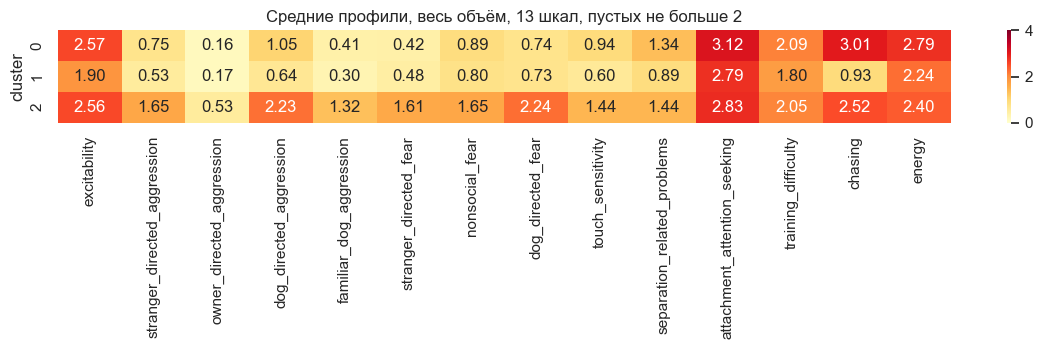

,session_id,dog_id,source,wave,cluster,cluster_size,n_scales_missing,excitability,owner_directed_aggression,dog_directed_aggression,familiar_dog_aggression,stranger_directed_fear,nonsocial_fear,dog_directed_fear,touch_sensitivity,separation_related_problems,attachment_attention_seeking,training_difficulty,chasing,energy
0,serpell_shelter_2009:MO:447556:na,MO:447556,serpell_shelter_2009,NaN,0,315,0,2.5,0.0,1.5,0.0,0.0,0.33,1.0,0.5,1.33,4.0,2.00,3.0,3.0
1,serpell_shelter_2009:CA:30344:na,CA:30344,serpell_shelter_2009,NaN,1,379,0,2.0,0.0,0.5,0.0,0.5,0.67,1.0,1.0,0.67,2.5,1.67,0.5,2.0
2,serpell_shelter_2009:CO:37248:na,CO:37248,serpell_shelter_2009,NaN,2,218,0,2.5,0.0,2.0,1.5,1.0,1.67,2.5,1.5,1.33,3.0,1.33,2.5,2.5


In [5]:
FEATURE_COLS = [col for col in SCALE_COLS if col != "stranger_directed_aggression"]


def drop_incomplete(frame: pd.DataFrame, label: str, max_missing: int = 2) -> pd.DataFrame:
    """Keep rows with at most max_missing empty subscales."""
    n_missing = frame[FEATURE_COLS].isna().sum(axis=1)
    keep = n_missing <= max_missing
    kept = frame.loc[keep].copy()
    print(
        f"{label}: {len(frame)} -> {len(kept)}, "
        f"dropped {int((~keep).sum())} (empty scales > {max_missing})"
    )
    return kept


def silhouette_by_seed(frame: pd.DataFrame, label: str) -> pd.DataFrame:
    """Silhouette for k=4..8 on each seed. Empty scales are filled with the slice median."""
    filled = frame[FEATURE_COLS].fillna(frame[FEATURE_COLS].median())
    if filled.isna().any().any():
        missing = filled.columns[filled.isna().any()].tolist()
        raise ValueError(f"{label}: subscale is empty in the whole slice: {missing}")
    X = filled.to_numpy(dtype=float)
    seeds = list(dict.fromkeys(SEEDS))
    rows = []
    for seed in seeds:
        for k in range(3, 9):
            labels = KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(X)
            rows.append({
                "seed": seed,
                "k": k,
                "silhouette": float(silhouette_score(X, labels)),
            })
    table = pd.DataFrame(rows)
    wide = table.pivot(index="seed", columns="k", values="silhouette")
    chosen = wide.idxmax(axis=1).astype(int)
    ref_k = int(chosen.loc[seeds[0]])
    band = wide[ref_k]
    same_k = int(chosen.nunique()) == 1
    spread = float(band.max() - band.min())
    stable = same_k and spread < 0.02
    print(label)
    print(wide.round(3).to_string())
    print("chosen k by seed:\n" + chosen.to_string())
    print(
        f"k={ref_k} (seed {seeds[0]}): "
        f"min {band.min():.3f}, max {band.max():.3f}, spread {spread:.3f}"
    )
    print("stable:", stable)
    return wide


domain_complete = drop_incomplete(domain_dedup, "all")
labeled_all_13, pool_all_13, scores_all_13 = fit_slice(
    domain_complete, "all, 13 scales", cols=FEATURE_COLS, random_state=SEED,
)
diverse_pool_13 = pool_table(pool_all_13, cols=FEATURE_COLS)
diverse_pool_13.to_csv(OUT_DIR / "diverse_pool_complete13.csv", index=False)
print(OUT_DIR / "diverse_pool_complete13.csv")
silhouette_all_13 = silhouette_by_seed(domain_complete, "all, 13 scales, seeds")
plot_means(labeled_all_13, "Средние профили, весь объём, 13 шкал, пустых не больше 2")
diverse_pool_13


## 5. Bohland, 10-й день, те же преобразования

Тот же фильтр: без `stranger_directed_aggression` и не больше двух пустых шкал. В пуле по-прежнему `raw_dog_id`.

bohland d7 complete 92 unique Animal ID 90
bohland d7, 13 scales rows 92 chosen k 3 silhouette 0.152
k
3    0.152
4    0.121
5    0.114
6    0.110
7    0.116
8    0.101
../datasets/unified/diverse_pool_bohland_d10_complete13.csv
bohland d7, 13 scales, seeds
k         3      4      5      6      7      8
seed                                          
13    0.152  0.113  0.102  0.099  0.123  0.116
21    0.150  0.118  0.114  0.094  0.107  0.115
42    0.152  0.121  0.114  0.110  0.116  0.101
666   0.152  0.107  0.118  0.103  0.106  0.114
999   0.150  0.120  0.115  0.114  0.088  0.101
chosen k by seed:
seed
13     3
21     3
42     3
666    3
999    3
k=3 (seed 42): min 0.150, max 0.152, spread 0.002
stable: True


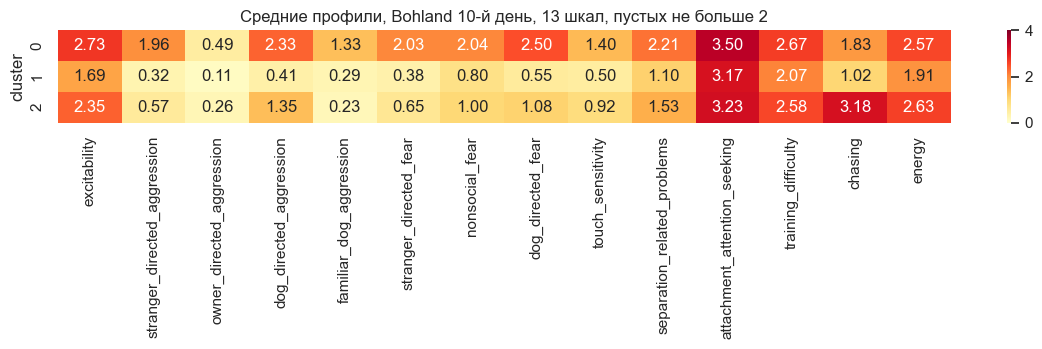

,session_id,dog_id,source,wave,raw_dog_id,cluster,cluster_size,n_scales_missing,excitability,owner_directed_aggression,...,familiar_dog_aggression,stranger_directed_fear,nonsocial_fear,dog_directed_fear,touch_sensitivity,separation_related_problems,attachment_attention_seeking,training_difficulty,chasing,energy
0,bohland_2023:rec46:d7,rec46,bohland_2023,d7,147134,0,15,0,3.0,0.33,...,0.5,1.5,2.00,2.0,1.0,1.67,4.0,2.0,1.0,3.0
1,bohland_2023:rec88:d7,rec88,bohland_2023,d7,147705,1,47,0,1.5,0.33,...,0.0,0.0,0.67,0.5,0.5,1.33,4.0,2.0,1.0,3.0
2,bohland_2023:rec79:d7,rec79,bohland_2023,d7,147420,2,30,0,2.5,0.00,...,0.0,2.0,1.00,1.0,1.5,1.00,4.0,2.0,3.0,2.5


In [6]:
bohland_d10_complete = domain_complete.loc[
    (domain_complete["source"] == "bohland_2023") & (domain_complete["wave"] == "d7")
].copy()
print(
    "bohland d7 complete",
    len(bohland_d10_complete),
    "unique Animal ID",
    bohland_d10_complete["raw_dog_id"].nunique(),
)
labeled_d10_13, pool_d10_13, scores_d10_13 = fit_slice(
    bohland_d10_complete, "bohland d7, 13 scales", cols=FEATURE_COLS, random_state=SEED,
)
diverse_pool_bohland_13 = pool_table(pool_d10_13, extra=["raw_dog_id"], cols=FEATURE_COLS)
diverse_pool_bohland_13.to_csv(OUT_DIR / "diverse_pool_bohland_d10_complete13.csv", index=False)
print(OUT_DIR / "diverse_pool_bohland_d10_complete13.csv")
silhouette_d10_13 = silhouette_by_seed(bohland_d10_complete, "bohland d7, 13 scales, seeds")
plot_means(labeled_d10_13, "Средние профили, Bohland 10-й день, 13 шкал, пустых не больше 2")
diverse_pool_bohland_13

## 6. Устойчивость при фиксированном `k = 3`

`k` задан как размер пула и больше не выбирается по силуэту. На каждом seed из `SEEDS` KMeans обучается один раз. Попарный adjusted Rand сравнивает разметки. Если средний ARI не ниже 0.8, кластеры от seed не ездят, и медоиды можно брать с `SEED = 42`. Срезы те же, что в разделах 4 и 5: 13 шкал, пустых не больше двух, пропуски для расстояния заполнены медианой.

In [7]:
POOL_K = 3
ARI_STABLE = 0.8


def pairwise_ari(frame: pd.DataFrame, cols: list[str], k: int, label: str) -> pd.DataFrame:
    """One KMeans per seed at a fixed k, then pairwise adjusted Rand."""
    filled = frame[cols].fillna(frame[cols].median())
    if filled.isna().any().any():
        missing = filled.columns[filled.isna().any()].tolist()
        raise ValueError(f"{label}: subscale is empty in the whole slice: {missing}")
    X = filled.to_numpy(dtype=float)
    seeds = list(dict.fromkeys(SEEDS))
    labels = {
        seed: KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(X)
        for seed in seeds
    }
    rows = []
    for i, left in enumerate(seeds):
        for right in seeds[i + 1:]:
            rows.append({
                "seed_a": left,
                "seed_b": right,
                "ari": float(adjusted_rand_score(labels[left], labels[right])),
            })
    pairs = pd.DataFrame(rows)
    mean_ari = float(pairs["ari"].mean())
    print(f"{label}: k={k}, pairs {len(pairs)}, mean ARI {mean_ari:.3f}")
    print(pairs.assign(ari=pairs["ari"].round(3)).to_string(index=False))
    print("clusters stable, medoids from SEED:", mean_ari >= ARI_STABLE)
    return pairs


ari_all = pairwise_ari(domain_complete, FEATURE_COLS, POOL_K, "all, 13 scales")
ari_d10 = pairwise_ari(bohland_d10_complete, FEATURE_COLS, POOL_K, "bohland d7, 13 scales")

all, 13 scales: k=3, pairs 10, mean ARI 0.977
 seed_a  seed_b   ari
     42      13 0.958
     42      21 0.958
     42     666 0.952
     42     999 0.948
     13      21 1.000
     13     666 0.993
     13     999 0.990
     21     666 0.993
     21     999 0.990
    666     999 0.989
clusters stable, medoids from SEED: True
bohland d7, 13 scales: k=3, pairs 10, mean ARI 0.938
 seed_a  seed_b   ari
     42      13 1.000
     42      21 0.888
     42     666 1.000
     42     999 0.940
     13      21 0.888
     13     666 1.000
     13     999 0.940
     21     666 0.888
     21     999 0.901
    666     999 0.940
clusters stable, medoids from SEED: True


## 7. Выгрузка классов

Два файла, в каждом только `animal_id` и `cluster`. Класс — метка KMeans из разделов 4 и 5 (`SEED`). Для Bohland `animal_id` — это `raw_dog_id`. На всём объёме то же поле; у PostAdoptionMini его нет, поэтому там стоит `dog_id`.

In [8]:
def export_classes(labeled: pd.DataFrame, path: Path) -> pd.DataFrame:
    """Write animal id and cluster number. One row per clustered questionnaire."""
    animal = labeled["raw_dog_id"]
    missing = animal.isna() | animal.astype(str).str.strip().isin(["", "nan", "None"])
    animal = animal.where(~missing, labeled["dog_id"])
    out = pd.DataFrame({
        "animal_id": animal.map(lambda value: str(value).removesuffix(".0")),
        "cluster": labeled["cluster"].astype(int),
    })
    out.to_csv(path, index=False)
    print(path, "rows", len(out), "clusters", sorted(out["cluster"].unique().tolist()))
    return out


# classes_all = export_classes(labeled_all_13, OUT_DIR / "clusters_all.csv")
classes_d10 = export_classes(labeled_d10_13, OUT_DIR / "clusters_bohland_d10.csv")
classes_d10

../datasets/unified/clusters_bohland_d10.csv rows 92 clusters [0, 1, 2]


,animal_id,cluster
0,145222,2
1,136712,1
2,143159,1
3,145171,2
4,143493,2
...,...,...
87,A46915866,1
88,A47841625,2
89,A47849309,1
90,148202,0
